<a href="https://colab.research.google.com/github/isem49/APP-Sorteio/blob/master/AnaliseStudant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest

# Versão não otimizada

Treinando o modelo e monitorando recursos computacionais...

1. CUSTO COMPUTACIONAL / OPERACIONAL (BASELINE)
Número de Variáveis (Features): 32
Amostras de Treinamento: 80000
Tempo de Treinamento: 20.5233 segundos
Tempo de Predição: 0.9422 segundos
Pico de Memória RAM: 73.27 MB

2. MÉTRICAS DE DESEMPENHO PREDITIVO
ROC-AUC Score: 0.8931
PR-AUC Score (Average Precision): 0.8100

                 precision    recall  f1-score   support

Permanência (0)       0.85      0.92      0.88     13599
     Evasão (1)       0.79      0.66      0.72      6401

       accuracy                           0.83     20000
      macro avg       0.82      0.79      0.80     20000
   weighted avg       0.83      0.83      0.83     20000



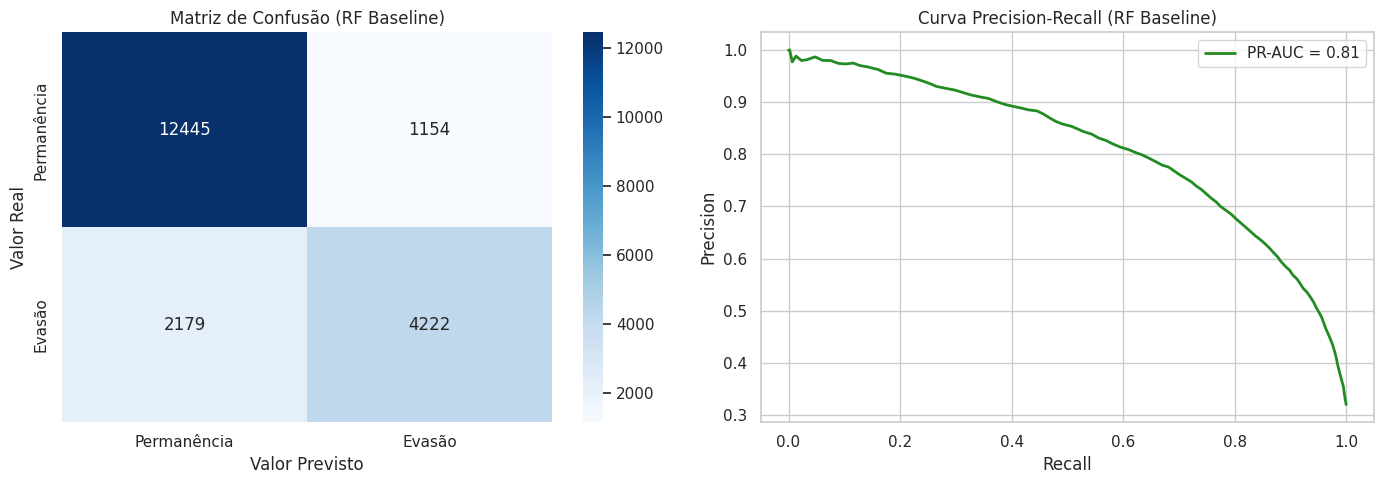

/tmp/ipykernel_2179/116792372.py:128: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['RF Baseline'], y=[tempo_treinamento], ax=axes_custo[0], palette=['#3498db'])
/tmp/ipykernel_2179/116792372.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['RF Baseline'], y=[pico_memoria_mb], ax=axes_custo[1], palette=['#9b59b6'])
/tmp/ipykernel_2179/116792372.py:140: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['RF Baseline'], y=[X.shape[1]], ax=axes_custo[2], palette=['#e67e22'])


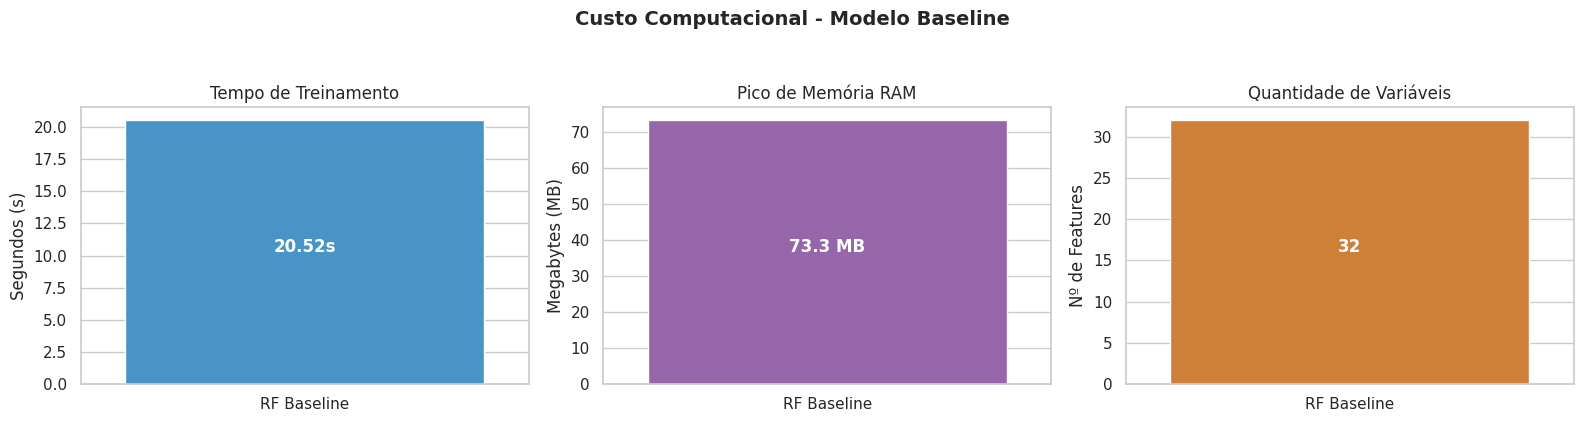

In [21]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Estilo visual para plots
sns.set_theme(style="whitegrid")

# 1. Carregar os Dados
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

# Separar Features (X) e Target (y)
X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

# Identificar colunas numéricas e categóricas
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Pré-processamento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# 4. Pipeline do Random Forest (Baseline Normal)
rf_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Treinando o modelo e monitorando recursos computacionais...")

# --- MEDIÇÃO DE CUSTO COMPUTACIONAL (Treinamento) ---
tracemalloc.start()
start_train_time = time.time()

rf_baseline.fit(X_train, y_train)

end_train_time = time.time()
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# --- MEDIÇÃO DE CUSTO COMPUTACIONAL (Predição) ---
start_pred_time = time.time()

y_pred_rf = rf_baseline.predict(X_test)
y_proba_rf = rf_baseline.predict_proba(X_test)[:, 1]

end_pred_time = time.time()

# Métricas de custo
tempo_treinamento = end_train_time - start_train_time
tempo_predicao = end_pred_time - start_pred_time
pico_memoria_mb = peak_mem / (1024 * 1024)

# 5. Apresentação das Métricas Operacionais
print("\n" + "="*50)
print("1. CUSTO COMPUTACIONAL / OPERACIONAL (BASELINE)")
print("="*50)
print(f"Número de Variáveis (Features): {X.shape[1]}")
print(f"Amostras de Treinamento: {X_train.shape[0]}")
print(f"Tempo de Treinamento: {tempo_treinamento:.4f} segundos")
print(f"Tempo de Predição: {tempo_predicao:.4f} segundos")
print(f"Pico de Memória RAM: {pico_memoria_mb:.2f} MB")

print("\n" + "="*50)
print("2. MÉTRICAS DE DESEMPENHO PREDITIVO")
print("="*50)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"PR-AUC Score (Average Precision): {average_precision_score(y_test, y_proba_rf):.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=['Permanência (0)', 'Evasão (1)']))

# -------------------------------------------------------------
# VISUALIZAÇÃO 1: Matriz de Confusão e Precision-Recall
# -------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Permanência', 'Evasão'], yticklabels=['Permanência', 'Evasão'])
ax[0].set_title('Matriz de Confusão (RF Baseline)')
ax[0].set_ylabel('Valor Real')
ax[0].set_xlabel('Valor Previsto')

precision, recall, _ = precision_recall_curve(y_test, y_proba_rf)
ax[1].plot(recall, precision, color='forestgreen', lw=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_rf):.2f}')
ax[1].set_title('Curva Precision-Recall (RF Baseline)')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# VISUALIZAÇÃO 2: Gráficos de Custo Computacional
# -------------------------------------------------------------
fig_custo, axes_custo = plt.subplots(1, 3, figsize=(16, 4))

# Gráfico 1: Tempo de Treino
sns.barplot(x=['RF Baseline'], y=[tempo_treinamento], ax=axes_custo[0], palette=['#3498db'])
axes_custo[0].set_title('Tempo de Treinamento')
axes_custo[0].set_ylabel('Segundos (s)')
axes_custo[0].annotate(f'{tempo_treinamento:.2f}s', (0, tempo_treinamento/2), ha='center', color='white', fontweight='bold')

# Gráfico 2: Consumo de Memória
sns.barplot(x=['RF Baseline'], y=[pico_memoria_mb], ax=axes_custo[1], palette=['#9b59b6'])
axes_custo[1].set_title('Pico de Memória RAM')
axes_custo[1].set_ylabel('Megabytes (MB)')
axes_custo[1].annotate(f'{pico_memoria_mb:.1f} MB', (0, pico_memoria_mb/2), ha='center', color='white', fontweight='bold')

# Gráfico 3: Número de Features
sns.barplot(x=['RF Baseline'], y=[X.shape[1]], ax=axes_custo[2], palette=['#e67e22'])
axes_custo[2].set_title('Quantidade de Variáveis')
axes_custo[2].set_ylabel('Nº de Features')
axes_custo[2].annotate(f'{X.shape[1]}', (0, X.shape[1]/2), ha='center', color='white', fontweight='bold')

plt.suptitle('Custo Computacional - Modelo Baseline', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Versão Otimizada

Treinando o Modelo Otimizado e monitorando recursos...

1. CUSTO COMPUTACIONAL / OPERACIONAL (MODELO OTIMIZADO)
Quantidade de Variáveis (Features): 15
Amostras Utilizadas no Treinamento: 40000
Tempo de Treinamento: 5.8917 segundos
Tempo de Predição (Inferência): 0.3163 segundos
Pico de Consumo de Memória RAM: 17.17 MB

2. DESEMPENHO PREDITIVO (MODELO OTIMIZADO)
ROC-AUC Score: 0.8878
PR-AUC Score (Average Precision): 0.8013

                 precision    recall  f1-score   support

Permanência (0)       0.88      0.84      0.86     13599
     Evasão (1)       0.69      0.76      0.73      6401

       accuracy                           0.82     20000
      macro avg       0.79      0.80      0.79     20000
   weighted avg       0.82      0.82      0.82     20000



/tmp/ipykernel_2179/1211665375.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#2ecc71', '#27ae60', '#1abc9c'])


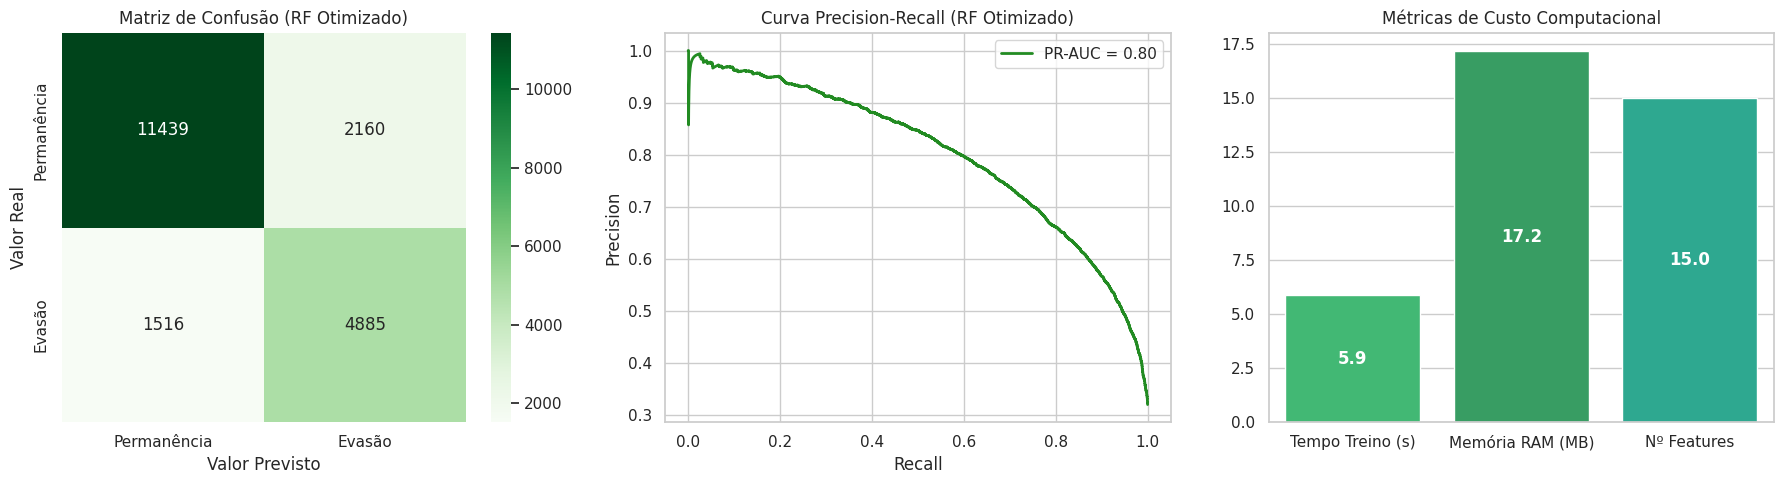

In [22]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Estilo visual
sns.set_theme(style="whitegrid")

# 1. CARREGAMENTO DOS DADOS
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

# Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# -------------------------------------------------------------
# APLICAÇÃO DAS 3 TÉCNICAS DE OTIMIZAÇÃO
# -------------------------------------------------------------

# TÉCNICA 1: SAMPLING (Amostragem do conjunto de treino)
# Utiliza 50% do treino para acelerar o tempo de execução e economizar RAM
X_train_opt, _, y_train_opt, _ = train_test_split(
    X_train, y_train, train_size=0.50, random_state=42, stratify=y_train
)

# TÉCNICA 2: FEATURE SELECTION (Seleção das 15 variáveis principais)
top_num_cols = [
    'attendance_rate', 'gpa_semester_2', 'gpa_semester_1', 'units_failed',
    'assignments_submitted_rate', 'lms_logins_per_week', 'missed_deadlines',
    'units_passed', 'tuition_up_to_date', 'admission_grade',
    'previous_qualification_grade', 'weekly_work_hours'
]
top_cat_cols = ['family_income_level', 'course_type', 'study_mode']

X_train_opt_feat = X_train_opt[top_num_cols + top_cat_cols]
X_test_opt_feat = X_test[top_num_cols + top_cat_cols]

# Pré-processador para as variáveis selecionadas
preprocessor_opt = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), top_num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), top_cat_cols)
    ]
)

# TÉCNICA 3: HYPERPARAMETER OPTIMIZATION (Configuração eficiente do RF)
rf_otimizado = Pipeline(steps=[
    ('preprocessor', preprocessor_opt),
    ('classifier', RandomForestClassifier(
        n_estimators=60,         # Menos árvores
        max_depth=12,            # Profundidade limitada
        min_samples_split=10,    # Reduz overfitting e complexidade por nó
        class_weight='balanced', # Balanceamento de classes
        random_state=42,
        n_jobs=-1
    ))
])

# -------------------------------------------------------------
# TREINAMENTO E MEDIÇÃO DE CUSTO COMPUTACIONAL
# -------------------------------------------------------------
print("Treinando o Modelo Otimizado e monitorando recursos...")

tracemalloc.start()
start_train_time = time.time()

rf_otimizado.fit(X_train_opt_feat, y_train_opt)

end_train_time = time.time()
_, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Predição e Probabilidades (Risk Score)
start_pred_time = time.time()
y_pred_opt = rf_otimizado.predict(X_test_opt_feat)
y_proba_opt = rf_otimizado.predict_proba(X_test_opt_feat)[:, 1]
end_pred_time = time.time()

# Cálculo de métricas computacionais
tempo_treinamento = end_train_time - start_train_time
tempo_predicao = end_pred_time - start_pred_time
pico_memoria_mb = peak_mem / (1024 * 1024)

# -------------------------------------------------------------
# EXIBIÇÃO DAS MÉTRICAS
# -------------------------------------------------------------
print("\n" + "="*50)
print("1. CUSTO COMPUTACIONAL / OPERACIONAL (MODELO OTIMIZADO)")
print("="*50)
print(f"Quantidade de Variáveis (Features): {len(top_num_cols + top_cat_cols)}")
print(f"Amostras Utilizadas no Treinamento: {X_train_opt_feat.shape[0]}")
print(f"Tempo de Treinamento: {tempo_treinamento:.4f} segundos")
print(f"Tempo de Predição (Inferência): {tempo_predicao:.4f} segundos")
print(f"Pico de Consumo de Memória RAM: {pico_memoria_mb:.2f} MB")

print("\n" + "="*50)
print("2. DESEMPENHO PREDITIVO (MODELO OTIMIZADO)")
print("="*50)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_opt):.4f}")
print(f"PR-AUC Score (Average Precision): {average_precision_score(y_test, y_proba_opt):.4f}\n")
print(classification_report(y_test, y_pred_opt, target_names=['Permanência (0)', 'Evasão (1)']))

# -------------------------------------------------------------
# VISUALIZACÕES GRÁFICAS
# -------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax[0],
            xticklabels=['Permanência', 'Evasão'], yticklabels=['Permanência', 'Evasão'])
ax[0].set_title('Matriz de Confusão (RF Otimizado)')
ax[0].set_ylabel('Valor Real')
ax[0].set_xlabel('Valor Previsto')

# Gráfico 2: Curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_proba_opt)
ax[1].plot(recall, precision, color='forestgreen', lw=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_opt):.2f}')
ax[1].set_title('Curva Precision-Recall (RF Otimizado)')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

# Gráfico 3: Custo Computacional do Modelo Otimizado
metricas_custo = ['Tempo Treino (s)', 'Memória RAM (MB)', 'Nº Features']
valores_custo = [tempo_treinamento, pico_memoria_mb, len(top_num_cols + top_cat_cols)]

sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#2ecc71', '#27ae60', '#1abc9c'])
ax[2].set_title('Métricas de Custo Computacional')
for p in ax[2].patches:
    ax[2].annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Comparativo


1. Treinando o Modelo Baseline...

2. Aplicando as 3 Técnicas de Otimização...

TABELA COMPARATIVA: BASELINE VS. MODELO OTIMIZADO
                   Métrica Baseline (Normal) Otimizado (Proposto)
Nº de Variáveis (Features)                32                   15
        Amostras de Treino             80000                40000
  Tempo de Treinamento (s)            22.00s                3.87s
  Pico de Memória RAM (MB)           73.3 MB              17.2 MB
             ROC-AUC Score            0.8931               0.8878
              PR-AUC Score            0.8100               0.8013


/tmp/ipykernel_2179/3856144519.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=tempos, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
/tmp/ipykernel_2179/3856144519.py:185: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=mems, ax=axes[1], palette=['#e74c3c', '#2ecc71'])
/tmp/ipykernel_2179/3856144519.py:193: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=feats, ax=axes[2], palette=['#e74c3c', '#2ecc71'])


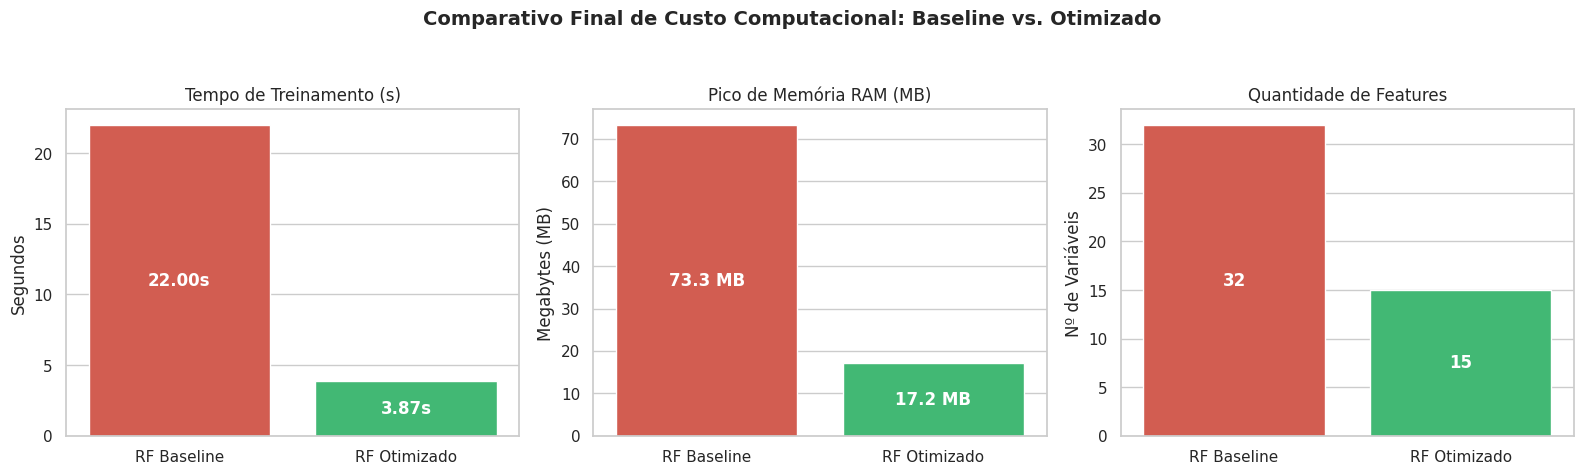

In [12]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Configuração de estilo visual
sns.set_theme(style="whitegrid")

# 1. CARREGAMENTO DOS DADOS
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# -------------------------------------------------------------
# ETAPA 1: EXECUÇÃO DO MODELO BASELINE (NORMAL)
# -------------------------------------------------------------
preprocessor_base = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

rf_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor_base),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

print("1. Treinando o Modelo Baseline...")
tracemalloc.start()
start_train_base = time.time()

rf_baseline.fit(X_train, y_train)

end_train_base = time.time()
_, peak_mem_base = tracemalloc.get_traced_memory()
tracemalloc.stop()

y_pred_base = rf_baseline.predict(X_test)
y_proba_base = rf_baseline.predict_proba(X_test)[:, 1]

tempo_base = end_train_base - start_train_base
memoria_base = peak_mem_base / (1024 * 1024)
roc_base = roc_auc_score(y_test, y_proba_base)
pr_base = average_precision_score(y_test, y_proba_base)

# -------------------------------------------------------------
# ETAPA 2: APLICAÇÃO DAS 3 TÉCNICAS DE OTIMIZAÇÃO
# -------------------------------------------------------------
print("\n2. Aplicando as 3 Técnicas de Otimização...")

# TÉCNICA 1: SAMPLING (Redução do conjunto de dados para treino)
# Mantém a proporção de classes, mas reduz o treino para 50% dos dados para economizar RAM/Tempo
X_train_opt, _, y_train_opt, _ = train_test_split(
    X_train, y_train, train_size=0.50, random_state=42, stratify=y_train
)

# TÉCNICA 2: FEATURE SELECTION (Seleção das 15 variáveis mais explicativas)
top_num_cols = [
    'attendance_rate', 'gpa_semester_2', 'gpa_semester_1', 'units_failed',
    'assignments_submitted_rate', 'lms_logins_per_week', 'missed_deadlines',
    'units_passed', 'tuition_up_to_date', 'admission_grade',
    'previous_qualification_grade', 'weekly_work_hours'
]
top_cat_cols = ['family_income_level', 'course_type', 'study_mode']

X_train_opt_feat = X_train_opt[top_num_cols + top_cat_cols]
X_test_opt_feat = X_test[top_num_cols + top_cat_cols]

preprocessor_opt = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), top_num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), top_cat_cols)
    ]
)

# TÉCNICA 3: HYPERPARAMETER OPTIMIZATION (Ajuste de Parâmetros Operacionais)
# Redução do número de árvores (100 -> 60), limite de profundidade (max_depth=12) e balanceamento
rf_otimizado = Pipeline(steps=[
    ('preprocessor', preprocessor_opt),
    ('classifier', RandomForestClassifier(
        n_estimators=60,         # Menos árvores
        max_depth=12,            # Profundidade controlada para evitar overfitting
        min_samples_split=10,    # Menor complexidade computacional por nó
        class_weight='balanced', # Tratamento do desbalanceamento
        random_state=42,
        n_jobs=-1
    ))
])

tracemalloc.start()
start_train_opt = time.time()

rf_otimizado.fit(X_train_opt_feat, y_train_opt)

end_train_opt = time.time()
_, peak_mem_opt = tracemalloc.get_traced_memory()
tracemalloc.stop()

y_pred_opt = rf_otimizado.predict(X_test_opt_feat)
y_proba_opt = rf_otimizado.predict_proba(X_test_opt_feat)[:, 1]

tempo_opt = end_train_opt - start_train_opt
memoria_opt = peak_mem_opt / (1024 * 1024)
roc_opt = roc_auc_score(y_test, y_proba_opt)
pr_opt = average_precision_score(y_test, y_proba_opt)

# -------------------------------------------------------------
# 3. EXIBIÇÃO DE RESULTADOS E TABELA COMPARATIVA
# -------------------------------------------------------------
df_comparativo = pd.DataFrame({
    'Métrica': [
        'Nº de Variáveis (Features)',
        'Amostras de Treino',
        'Tempo de Treinamento (s)',
        'Pico de Memória RAM (MB)',
        'ROC-AUC Score',
        'PR-AUC Score'
    ],
    'Baseline (Normal)': [
        X.shape[1],
        X_train.shape[0],
        f"{tempo_base:.2f}s",
        f"{memoria_base:.1f} MB",
        f"{roc_base:.4f}",
        f"{pr_base:.4f}"
    ],
    'Otimizado (Proposto)': [
        len(top_num_cols + top_cat_cols),
        X_train_opt.shape[0],
        f"{tempo_opt:.2f}s",
        f"{memoria_opt:.1f} MB",
        f"{roc_opt:.4f}",
        f"{pr_opt:.4f}"
    ]
})

print("\n" + "="*60)
print("TABELA COMPARATIVA: BASELINE VS. MODELO OTIMIZADO")
print("="*60)
print(df_comparativo.to_string(index=False))

# -------------------------------------------------------------
# 4. GRÁFICOS DE CUSTO COMPUTACIONAL E DESEMPENHO
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

modelos = ['RF Baseline', 'RF Otimizado']
tempos = [tempo_base, tempo_opt]
mems = [memoria_base, memoria_opt]
feats = [X.shape[1], len(top_num_cols + top_cat_cols)]

# Gráfico 1: Tempo de Treinamento
sns.barplot(x=modelos, y=tempos, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Tempo de Treinamento (s)')
axes[0].set_ylabel('Segundos')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}s', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico 2: Consumo de Memória RAM
sns.barplot(x=modelos, y=mems, ax=axes[1], palette=['#e74c3c', '#2ecc71'])
axes[1].set_title('Pico de Memória RAM (MB)')
axes[1].set_ylabel('Megabytes (MB)')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f} MB', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico 3: Número de Variáveis
sns.barplot(x=modelos, y=feats, ax=axes[2], palette=['#e74c3c', '#2ecc71'])
axes[2].set_title('Quantidade de Features')
axes[2].set_ylabel('Nº de Variáveis')
for p in axes[2].patches:
    axes[2].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

plt.suptitle('Comparativo Final de Custo Computacional: Baseline vs. Otimizado', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Decision Tree

# Não otimizada

Treinando a Árvore de Decisão Baseline (Não Otimizada)...

1. CUSTO COMPUTACIONAL / OPERACIONAL (DT BASELINE)
Quantidade de Variáveis (Features): 32
Amostras Utilizadas no Treinamento: 80000
Tempo de Treinamento: 4.9159 segundos
Tempo de Predição (Inferência): 0.1449 segundos
Pico de Consumo de Memória RAM: 73.27 MB

2. DESEMPENHO PREDITIVO (DT BASELINE)
ROC-AUC Score: 0.7179
PR-AUC Score (Average Precision): 0.5009

                 precision    recall  f1-score   support

Permanência (0)       0.82      0.81      0.82     13599
     Evasão (1)       0.61      0.62      0.62      6401

       accuracy                           0.75     20000
      macro avg       0.72      0.72      0.72     20000
   weighted avg       0.75      0.75      0.75     20000



/tmp/ipykernel_2179/3016315931.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#e67e22', '#d35400', '#f39c12'])


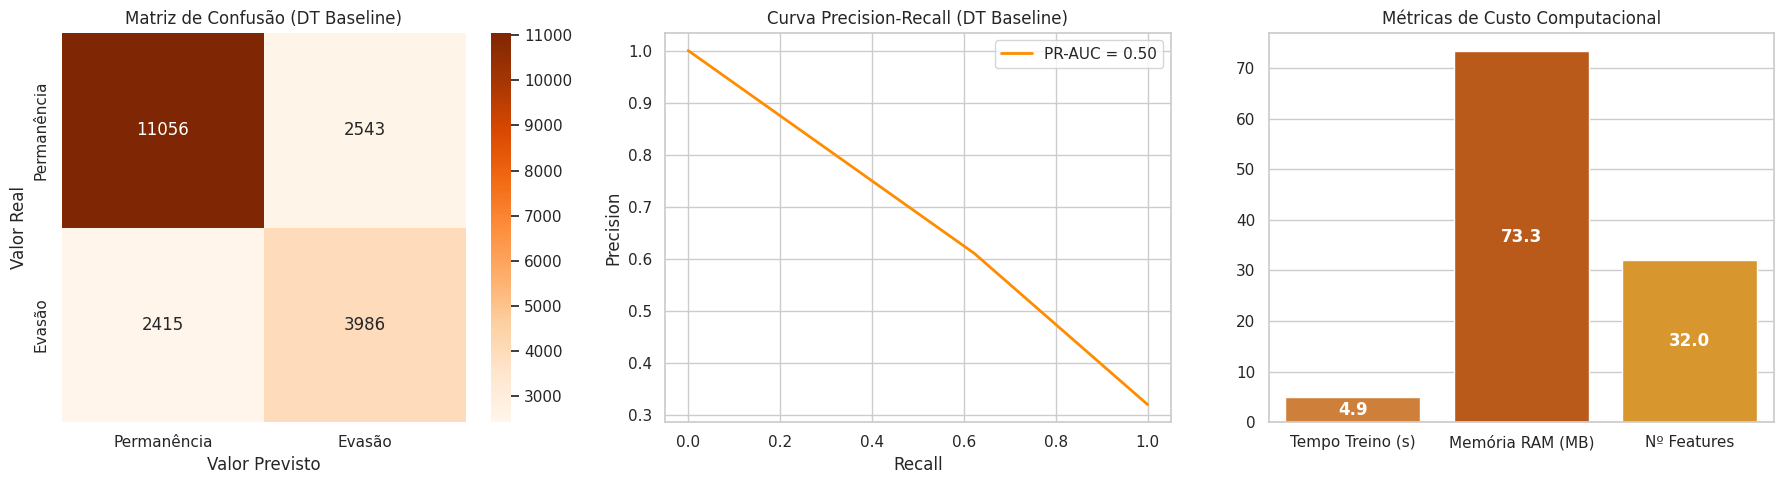

In [23]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Configuração de estilo visual
sns.set_theme(style="whitegrid")

# 1. CARREGAMENTO DOS DADOS
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. PRÉ-PROCESSAMENTO DOS DADOS
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

# 3. CONSTRUÇÃO DA PIPELINE (Decision Tree Padrão / Sem Otimização)
dt_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# 4. TREINAMENTO E MEDIÇÃO DE CUSTO COMPUTACIONAL
print("Treinando a Árvore de Decisão Baseline (Não Otimizada)...")

tracemalloc.start()
start_train_time = time.time()

dt_baseline.fit(X_train, y_train)

end_train_time = time.time()
_, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Predição e Probabilidades
start_pred_time = time.time()
y_pred_dt = dt_baseline.predict(X_test)
y_proba_dt = dt_baseline.predict_proba(X_test)[:, 1]
end_pred_time = time.time()

# Cálculo das métricas de custo
tempo_treinamento = end_train_time - start_train_time
tempo_predicao = end_pred_time - start_pred_time
pico_memoria_mb = peak_mem / (1024 * 1024)

# 5. EXIBIÇÃO DOS RESULTADOS
print("\n" + "="*50)
print("1. CUSTO COMPUTACIONAL / OPERACIONAL (DT BASELINE)")
print("="*50)
print(f"Quantidade de Variáveis (Features): {X.shape[1]}")
print(f"Amostras Utilizadas no Treinamento: {X_train.shape[0]}")
print(f"Tempo de Treinamento: {tempo_treinamento:.4f} segundos")
print(f"Tempo de Predição (Inferência): {tempo_predicao:.4f} segundos")
print(f"Pico de Consumo de Memória RAM: {pico_memoria_mb:.2f} MB")

print("\n" + "="*50)
print("2. DESEMPENHO PREDITIVO (DT BASELINE)")
print("="*50)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_dt):.4f}")
print(f"PR-AUC Score (Average Precision): {average_precision_score(y_test, y_proba_dt):.4f}\n")
print(classification_report(y_test, y_pred_dt, target_names=['Permanência (0)', 'Evasão (1)']))

# 6. GRÁFICOS VISUAIS
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax[0],
            xticklabels=['Permanência', 'Evasão'], yticklabels=['Permanência', 'Evasão'])
ax[0].set_title('Matriz de Confusão (DT Baseline)')
ax[0].set_ylabel('Valor Real')
ax[0].set_xlabel('Valor Previsto')

# Gráfico 2: Curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_proba_dt)
ax[1].plot(recall, precision, color='darkorange', lw=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_dt):.2f}')
ax[1].set_title('Curva Precision-Recall (DT Baseline)')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

# Gráfico 3: Métricas de Custo Computacional
metricas_custo = ['Tempo Treino (s)', 'Memória RAM (MB)', 'Nº Features']
valores_custo = [tempo_treinamento, pico_memoria_mb, X.shape[1]]

sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#e67e22', '#d35400', '#f39c12'])
ax[2].set_title('Métricas de Custo Computacional')
for p in ax[2].patches:
    ax[2].annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Otimizada

Treinando a Árvore de Decisão Otimizada e monitorando recursos...

1. CUSTO COMPUTACIONAL / OPERACIONAL (DT OTIMIZADA)
Quantidade de Variáveis (Features): 15
Amostras Utilizadas no Treinamento: 40000
Tempo de Treinamento: 0.4459 segundos
Tempo de Predição (Inferência): 0.0495 segundos
Pico de Consumo de Memória RAM: 15.59 MB

2. DESEMPENHO PREDITIVO (DT OTIMIZADA)
ROC-AUC Score: 0.8662
PR-AUC Score (Average Precision): 0.7590

                 precision    recall  f1-score   support

Permanência (0)       0.89      0.78      0.83     13599
     Evasão (1)       0.63      0.78      0.70      6401

       accuracy                           0.78     20000
      macro avg       0.76      0.78      0.76     20000
   weighted avg       0.80      0.78      0.79     20000



/tmp/ipykernel_2179/4176619691.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#e67e22', '#d35400', '#f39c12'])


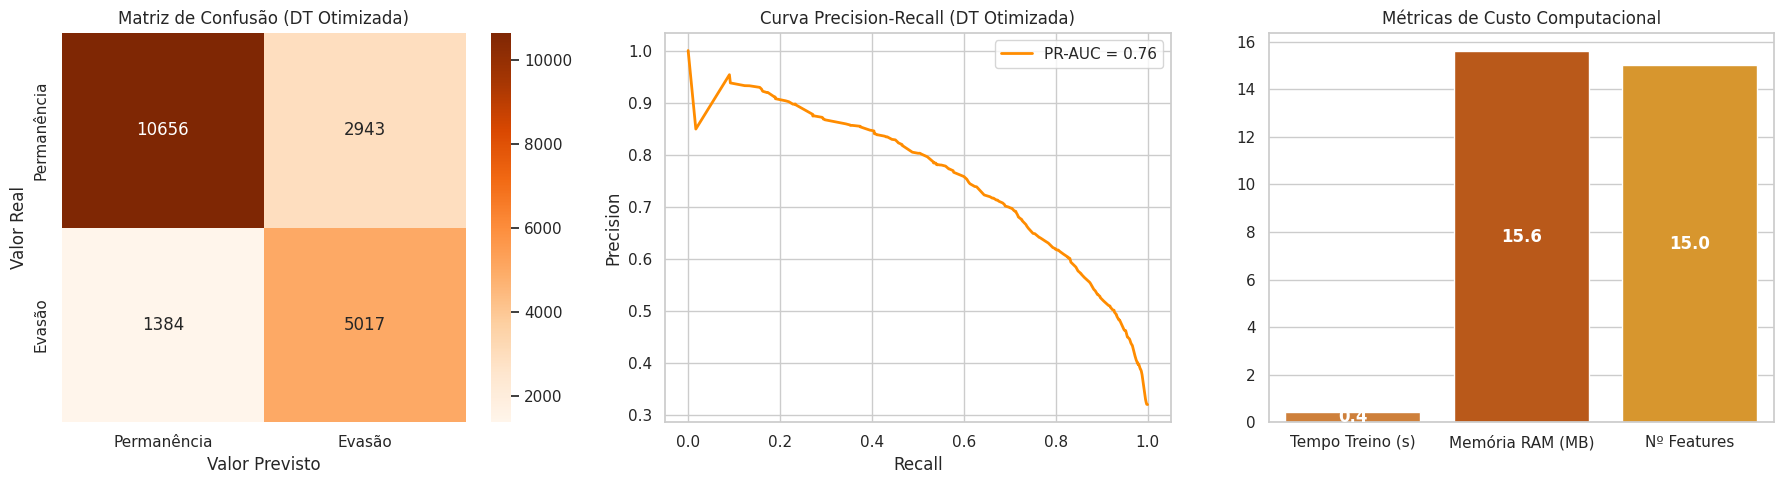

In [24]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Estilo visual
sns.set_theme(style="whitegrid")

# 1. CARREGAMENTO DOS DADOS
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

# Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# -------------------------------------------------------------
# APLICAÇÃO DAS 3 TÉCNICAS DE OTIMIZAÇÃO (DECISION TREE)
# -------------------------------------------------------------

# TÉCNICA 1: SAMPLING (Amostragem do conjunto de treino)
# Reduz o conjunto de treino para 50% para acelerar a execução e poupar RAM
X_train_opt, _, y_train_opt, _ = train_test_split(
    X_train, y_train, train_size=0.50, random_state=42, stratify=y_train
)

# TÉCNICA 2: FEATURE SELECTION (Seleção das 15 variáveis principais)
top_num_cols = [
    'attendance_rate', 'gpa_semester_2', 'gpa_semester_1', 'units_failed',
    'assignments_submitted_rate', 'lms_logins_per_week', 'missed_deadlines',
    'units_passed', 'tuition_up_to_date', 'admission_grade',
    'previous_qualification_grade', 'weekly_work_hours'
]
top_cat_cols = ['family_income_level', 'course_type', 'study_mode']

X_train_opt_feat = X_train_opt[top_num_cols + top_cat_cols]
X_test_opt_feat = X_test[top_num_cols + top_cat_cols]

# Pré-processador para as variáveis selecionadas
preprocessor_opt = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), top_num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), top_cat_cols)
    ]
)

# TÉCNICA 3: HYPERPARAMETER OPTIMIZATION (Poda e Configuração Eficiente)
dt_otimizado = Pipeline(steps=[
    ('preprocessor', preprocessor_opt),
    ('classifier', DecisionTreeClassifier(
        max_depth=8,              # Poda da árvore para evitar overfitting
        min_samples_split=20,     # Exige mais amostras para dividir nós
        min_samples_leaf=10,      # Evita folhas isoladas
        class_weight='balanced',  # Trata o desbalanceamento das classes
        random_state=42
    ))
])

# -------------------------------------------------------------
# TREINAMENTO E MEDIÇÃO DE CUSTO COMPUTACIONAL
# -------------------------------------------------------------
print("Treinando a Árvore de Decisão Otimizada e monitorando recursos...")

tracemalloc.start()
start_train_time = time.time()

dt_otimizado.fit(X_train_opt_feat, y_train_opt)

end_train_time = time.time()
_, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Predição e Probabilidades (Risk Score)
start_pred_time = time.time()
y_pred_dt_opt = dt_otimizado.predict(X_test_opt_feat)
y_proba_dt_opt = dt_otimizado.predict_proba(X_test_opt_feat)[:, 1]
end_pred_time = time.time()

# Cálculo das métricas de custo
tempo_treinamento = end_train_time - start_train_time
tempo_predicao = end_pred_time - start_pred_time
pico_memoria_mb = peak_mem / (1024 * 1024)

# -------------------------------------------------------------
# EXIBIÇÃO DAS MÉTRICAS
# -------------------------------------------------------------
print("\n" + "="*50)
print("1. CUSTO COMPUTACIONAL / OPERACIONAL (DT OTIMIZADA)")
print("="*50)
print(f"Quantidade de Variáveis (Features): {len(top_num_cols + top_cat_cols)}")
print(f"Amostras Utilizadas no Treinamento: {X_train_opt_feat.shape[0]}")
print(f"Tempo de Treinamento: {tempo_treinamento:.4f} segundos")
print(f"Tempo de Predição (Inferência): {tempo_predicao:.4f} segundos")
print(f"Pico de Consumo de Memória RAM: {pico_memoria_mb:.2f} MB")

print("\n" + "="*50)
print("2. DESEMPENHO PREDITIVO (DT OTIMIZADA)")
print("="*50)
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_dt_opt):.4f}")
print(f"PR-AUC Score (Average Precision): {average_precision_score(y_test, y_proba_dt_opt):.4f}\n")
print(classification_report(y_test, y_pred_dt_opt, target_names=['Permanência (0)', 'Evasão (1)']))

# -------------------------------------------------------------
# VISUALIZAÇÕES GRÁFICAS
# -------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_dt_opt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax[0],
            xticklabels=['Permanência', 'Evasão'], yticklabels=['Permanência', 'Evasão'])
ax[0].set_title('Matriz de Confusão (DT Otimizada)')
ax[0].set_ylabel('Valor Real')
ax[0].set_xlabel('Valor Previsto')

# Gráfico 2: Curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_test, y_proba_dt_opt)
ax[1].plot(recall, precision, color='darkorange', lw=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_dt_opt):.2f}')
ax[1].set_title('Curva Precision-Recall (DT Otimizada)')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend()

# Gráfico 3: Custo Computacional do Modelo Otimizado
metricas_custo = ['Tempo Treino (s)', 'Memória RAM (MB)', 'Nº Features']
valores_custo = [tempo_treinamento, pico_memoria_mb, len(top_num_cols + top_cat_cols)]

sns.barplot(x=metricas_custo, y=valores_custo, ax=ax[2], palette=['#e67e22', '#d35400', '#f39c12'])
ax[2].set_title('Métricas de Custo Computacional')
for p in ax[2].patches:
    ax[2].annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Comparativo

1. Treinando a Decision Tree Baseline...

2. Aplicando as 3 Técnicas de Otimização na Decision Tree...

TABELA COMPARATIVA: DECISION TREE BASELINE VS. OTIMIZADA
                   Métrica DT Baseline DT Otimizada
Nº de Variáveis (Features)          32           15
        Amostras de Treino       80000        40000
  Tempo de Treinamento (s)       5.73s        0.68s
  Pico de Memória RAM (MB)     73.3 MB      15.6 MB
             ROC-AUC Score      0.7179       0.8662
              PR-AUC Score      0.5009       0.7590


/tmp/ipykernel_2179/1136648807.py:174: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=tempos, ax=axes[0], palette=['#e67e22', '#2ecc71'])
/tmp/ipykernel_2179/1136648807.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=mems, ax=axes[1], palette=['#e67e22', '#2ecc71'])
/tmp/ipykernel_2179/1136648807.py:190: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelos, y=feats, ax=axes[2], palette=['#e67e22', '#2ecc71'])


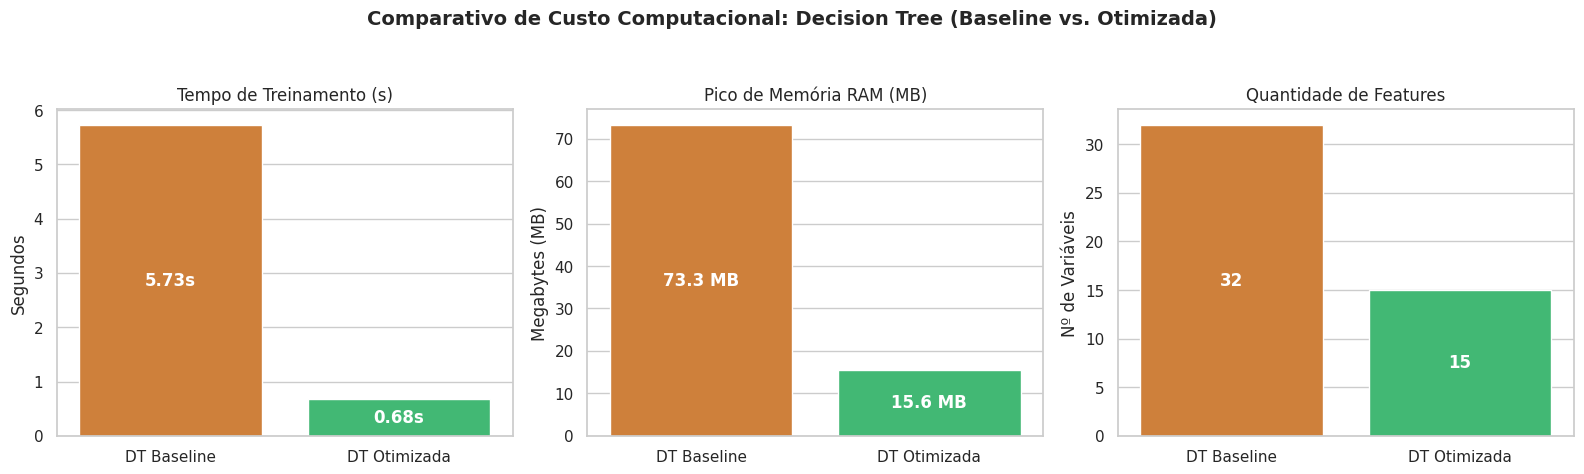

In [20]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Configuração de estilo visual
sns.set_theme(style="whitegrid")

# 1. CARREGAMENTO DOS DADOS
df = pd.read_csv("/content/sample_data/student_dropout_risk_2026.csv")

X = df.drop(columns=['person_id', 'dropout'])
y = df['dropout']

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Divisão Treino e Teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# -------------------------------------------------------------
# ETAPA 1: EXECUÇÃO DA DECISION TREE BASELINE (NÃO OTIMIZADA)
# -------------------------------------------------------------
preprocessor_base = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

dt_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor_base),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

print("1. Treinando a Decision Tree Baseline...")
tracemalloc.start()
start_train_base = time.time()

dt_baseline.fit(X_train, y_train)

end_train_base = time.time()
_, peak_mem_base = tracemalloc.get_traced_memory()
tracemalloc.stop()

y_pred_base = dt_baseline.predict(X_test)
y_proba_base = dt_baseline.predict_proba(X_test)[:, 1]

tempo_base = end_train_base - start_train_base
memoria_base = peak_mem_base / (1024 * 1024)
roc_base = roc_auc_score(y_test, y_proba_base)
pr_base = average_precision_score(y_test, y_proba_base)

# -------------------------------------------------------------
# ETAPA 2: APLICAÇÃO DAS 3 TÉCNICAS DE OTIMIZAÇÃO NA DECISION TREE
# -------------------------------------------------------------
print("\n2. Aplicando as 3 Técnicas de Otimização na Decision Tree...")

# TÉCNICA 1: SAMPLING (Uso de 50% dos dados para treino)
X_train_opt, _, y_train_opt, _ = train_test_split(
    X_train, y_train, train_size=0.50, random_state=42, stratify=y_train
)

# TÉCNICA 2: FEATURE SELECTION (Seleção das 15 variáveis principais)
top_num_cols = [
    'attendance_rate', 'gpa_semester_2', 'gpa_semester_1', 'units_failed',
    'assignments_submitted_rate', 'lms_logins_per_week', 'missed_deadlines',
    'units_passed', 'tuition_up_to_date', 'admission_grade',
    'previous_qualification_grade', 'weekly_work_hours'
]
top_cat_cols = ['family_income_level', 'course_type', 'study_mode']

X_train_opt_feat = X_train_opt[top_num_cols + top_cat_cols]
X_test_opt_feat = X_test[top_num_cols + top_cat_cols]

preprocessor_opt = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), top_num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), top_cat_cols)
    ]
)

# TÉCNICA 3: HYPERPARAMETER OPTIMIZATION (Poda e balanceamento)
dt_otimizado = Pipeline(steps=[
    ('preprocessor', preprocessor_opt),
    ('classifier', DecisionTreeClassifier(
        max_depth=8,              # Poda para conter overfitting
        min_samples_split=20,     # Mínimo de amostras por divisão
        min_samples_leaf=10,      # Mínimo de amostras por folha
        class_weight='balanced',  # Ajuste para classe minoritária
        random_state=42
    ))
])

tracemalloc.start()
start_train_opt = time.time()

dt_otimizado.fit(X_train_opt_feat, y_train_opt)

end_train_opt = time.time()
_, peak_mem_opt = tracemalloc.get_traced_memory()
tracemalloc.stop()

y_pred_opt = dt_otimizado.predict(X_test_opt_feat)
y_proba_opt = dt_otimizado.predict_proba(X_test_opt_feat)[:, 1]

tempo_opt = end_train_opt - start_train_opt
memoria_opt = peak_mem_opt / (1024 * 1024)
roc_opt = roc_auc_score(y_test, y_proba_opt)
pr_opt = average_precision_score(y_test, y_proba_opt)

# -------------------------------------------------------------
# 3. EXIBIÇÃO DA TABELA COMPARATIVA
# -------------------------------------------------------------
df_comparativo = pd.DataFrame({
    'Métrica': [
        'Nº de Variáveis (Features)',
        'Amostras de Treino',
        'Tempo de Treinamento (s)',
        'Pico de Memória RAM (MB)',
        'ROC-AUC Score',
        'PR-AUC Score'
    ],
    'DT Baseline': [
        X.shape[1],
        X_train.shape[0],
        f"{tempo_base:.2f}s",
        f"{memoria_base:.1f} MB",
        f"{roc_base:.4f}",
        f"{pr_base:.4f}"
    ],
    'DT Otimizada': [
        len(top_num_cols + top_cat_cols),
        X_train_opt.shape[0],
        f"{tempo_opt:.2f}s",
        f"{memoria_opt:.1f} MB",
        f"{roc_opt:.4f}",
        f"{pr_opt:.4f}"
    ]
})

print("\n" + "="*60)
print("TABELA COMPARATIVA: DECISION TREE BASELINE VS. OTIMIZADA")
print("="*60)
print(df_comparativo.to_string(index=False))

# -------------------------------------------------------------
# 4. GRÁFICOS VISUAIS DE CUSTO COMPUTACIONAL
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

modelos = ['DT Baseline', 'DT Otimizada']
tempos = [tempo_base, tempo_opt]
mems = [memoria_base, memoria_opt]
feats = [X.shape[1], len(top_num_cols + top_cat_cols)]

# Gráfico 1: Tempo de Treinamento
sns.barplot(x=modelos, y=tempos, ax=axes[0], palette=['#e67e22', '#2ecc71'])
axes[0].set_title('Tempo de Treinamento (s)')
axes[0].set_ylabel('Segundos')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}s', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico 2: Consumo de Memória RAM
sns.barplot(x=modelos, y=mems, ax=axes[1], palette=['#e67e22', '#2ecc71'])
axes[1].set_title('Pico de Memória RAM (MB)')
axes[1].set_ylabel('Megabytes (MB)')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f} MB', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico 3: Número de Variáveis
sns.barplot(x=modelos, y=feats, ax=axes[2], palette=['#e67e22', '#2ecc71'])
axes[2].set_title('Quantidade de Features')
axes[2].set_ylabel('Nº de Variáveis')
for p in axes[2].patches:
    axes[2].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

plt.suptitle('Comparativo de Custo Computacional: Decision Tree (Baseline vs. Otimizada)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()